# PREDICCION EN EL DIAGNOSTICO DE DENGUE

DATA: https://data.mendeley.com/datasets/t2h5528tc4/1
Naim, Md Niazul Islam; Hasan, Abir (2026), “Early Detection of Dengue Infection Using Machine Learning: A Survey Dataset from Bangladesh”, Mendeley Data, V1, doi: 10.17632/t2h5528tc4.1

## 1 EDA

In [41]:
import pandas as pd
df = pd.read_csv('RAW.csv')
df.head()

,age,gender,district,area_type,ever_dengue,household_dengue_exposure_14d,stagnant_water,fever_days,max_temperature_f,headache_severity,...,vomiting_per_day,early_nausea,early_rash,early_bleeding,early_abdominal_pain,early_fatigue,early_appetite_loss,early_chills,early_diarrhea,dengue_result
0,30,Male (পুরুষ),Naogaon,Municipality / Semi-urban Area (পৌরসভা / আধা-শ...,No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),4,103,7,...,2,Yes (হ্যাঁ),Yes (হ্যাঁ),No (না),No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),No (না),Yes (হ্যাঁ),Dengue Positive (ডেঙ্গু পজিটিভ)
1,38,Male (পুরুষ),Shariatpur,Municipality / Semi-urban Area (পৌরসভা / আধা-শ...,No (না),No (না),Yes (হ্যাঁ),9,105,9,...,6,Yes (হ্যাঁ),Yes (হ্যাঁ),No (না),No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),No (না),Yes (হ্যাঁ),Dengue Positive (ডেঙ্গু পজিটিভ)
2,27,Male (পুরুষ),Munshiganj,Village / Rural Area (গ্রাম / পল্লি অঞ্চল),No (না),No (না),Yes (হ্যাঁ),5,107,10,...,6,Yes (হ্যাঁ),No (না),No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),Yes (হ্যাঁ),Yes (হ্যাঁ),No (না),Dengue Positive (ডেঙ্গু পজিটিভ)
3,35,Male (পুরুষ),Madaripur,Municipality / Semi-urban Area (পৌরসভা / আধা-শ...,No (না),No (না),No (না),13,104,10,...,1,Yes (হ্যাঁ),No (না),No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),Yes (হ্যাঁ),Yes (হ্যাঁ),Yes (হ্যাঁ),Dengue Positive (ডেঙ্গু পজিটিভ)
4,44,Male (পুরুষ),Faridpur,Municipality / Semi-urban Area (পৌরসভা / আধা-শ...,No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),7,106,6,...,5,Yes (হ্যাঁ),No (না),No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),Yes (হ্যাঁ),Yes (হ্যাঁ),No (না),Dengue Negative (ডেঙ্গু নেগেটিভ)


# Diccionario de Datos: Diagnóstico Clínico y Epidemiológico de Dengue

| Variable | Descripción Clínica / Epidemiológica | Unidad / Tipo de Dato | Notas de Auditoría y Calidad de Datos |
| :--- | :--- | :--- | :--- |
| `age` | Edad reportada por el paciente. | Años (Numérica) | Unidad no explícita en la encuesta original; se asume años (requiere validación de rango). |
| `gender` | Género reportado. | Categórica | Nominal. |
| `district` | Distrito de residencia actual en Bangladesh. | Categórica | Variable geográfica útil para análisis espacial de brotes. |
| `area_type` | Entorno de residencia actual (urbano, semiurbano o rural). | Categórica | Factor clave de densidad vectorial (*Aedes aegypti*). |
| `ever_dengue` | Antecedente de diagnóstico previo de dengue confirmado por un profesional de salud. | Categórica (Binaria) | **Riesgo de sesgo:** No especifica si el diagnóstico fue previo al episodio actual. Evaluar posible fuga de datos (*data leakage*). |
| `household_dengue_exposure_14d` | Contacto o casos confirmados de dengue en el hogar o entorno cercano en los últimos 14 días. | Categórica (Binaria) | Indicador epidemiológico de transmisión activa peridomiciliaria. |
| `stagnant_water` | Presencia visible de agua estancada (macetas, neumáticos, drenajes abiertos) cerca de la vivienda. | Categórica (Binaria) | Indicador ambiental de criaderos de mosquitos. |
| `fever_days` | Duración total de la fiebre durante la enfermedad (`0` si no presentó fiebre). | Días (Numérica entera) | Útil para estimar la fase de la enfermedad (febril, crítica o recuperación). |
| `max_temperature_f` | Temperatura corporal máxima registrada durante el cuadro clínico. | Grados Fahrenheit (°F) | Considerar conversión a °C (`(°F - 32) * 5/9`) para estandarización clínica internacional. |
| `headache_severity` | Intensidad máxima del dolor de cabeza. | Escala 0–10 (Ordinal) | `0` = ausencia de síntoma, `10` = dolor máximo. |
| `retro_orbital_pain` | Intensidad del dolor retroocular (detrás de los ojos). | Escala 0–10 (Ordinal) | Síntoma clásico orientador en el diagnóstico diferencial de dengue. |
| `muscle_pain` | Intensidad de las mialgias (dolor muscular). | Escala 0–10 (Ordinal) | Parte del cuadro clínico típico ("fiebre quebrantahuesos"). |
| `joint_pain` | Intensidad de las artralgias (dolor articular). | Escala 0–10 (Ordinal) | Evaluar colinealidad con `muscle_pain` durante el modelado. |
| `vomiting_per_day` | Frecuencia promedio de episodios de vómito al día durante la enfermedad. | Episodios/día (Numérica) | El vómito persistente es un signo de alarma según la OMS. |
| `early_nausea` | Presencia de náuseas en la fase temprana (días 1 a 3). | Categórica (Binaria) | Síntoma gastrointestinal temprano. |
| `early_rash` | Presencia de erupción cutánea (exantema) en la fase temprana (días 1 a 3). | Categórica (Binaria) | Manifestación dermatológica inicial. |
| `early_bleeding` | Sangrado (ej. epistaxis o gingivorragia) en la fase temprana (días 1 a 3). | Categórica (Binaria) | **Signo de alarma crítico** (sangrado de mucosas). |
| `early_abdominal_pain` | Dolor abdominal intenso en la fase temprana (días 1 a 3). | Categórica (Binaria) | **Signo de alarma crítico** según guías clínicas de la OMS. |
| `early_fatigue` | Fatiga o debilidad inusual en la fase temprana (días 1 a 3). | Categórica (Binaria) | Puede asociarse a letargo o inquietud (signo de alarma). |
| `early_appetite_loss` | Pérdida de apetito (hiporexia/anorexia) en la fase temprana (días 1 a 3). | Categórica (Binaria) | Síntoma constitucional inespecífico. |
| `early_chills` | Escalofríos o temblores en la fase temprana (días 1 a 3). | Categórica (Binaria) | Asociado a los picos febriles iniciales. |
| `early_diarrhea` | Diarrea en la fase temprana (días 1 a 3). | Categórica (Binaria) | Diagnóstico diferencial importante frente a gastroenteritis infecciosa. |
| `dengue_result` | **Variable objetivo (Target):** Resultado final de la prueba diagnóstica de dengue. | Categórica (Binaria/Multiclase) | **Limitación metodológica:** Se desconoce el tipo de prueba (NS1, IgM/IgG, PCR) y el día de toma de muestra. |


In [42]:
import re

# 1. Cargar los datos
df = pd.read_csv('RAW.csv')

# 2. Identificar las columnas de tipo texto (categóricas)
cols_texto = df.select_dtypes(include=['object']).columns

# 3. Función de limpieza: elimina todo lo que esté entre paréntesis (...) y espacios extra
def limpiar_texto(valor):
    if pd.isna(valor):
        return valor
    # Elimina paréntesis y su contenido (incluyendo caracteres bengalíes)
    limpio = re.sub(r'\s*\(.*?\)', '', str(valor))
    return limpio.strip()

# 4. Aplicar la limpieza a todas las columnas de texto
for col in cols_texto:
    df[col] = df[col].apply(limpiar_texto)

# 5. Verificar los valores únicos limpios en cada columna categórica
for col in cols_texto:
    print(f"--- {col} ---")
    print(df[col].unique())


--- gender ---
<ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str
--- district ---
<ArrowStringArray>
[    'Naogaon',  'Shariatpur',  'Munshiganj',   'Madaripur',    'Faridpur',
       'Dhaka', 'Narayanganj',     'Gazipur',   'Manikganj',   'Munsiganj',
   'Narsingdi',     'gazipur',  'Mymensingh',     'Cumilla',    'Barishal',
     'Tangail',     'Chadpur',  'Lakshmipur',    'Noakhali',  'Kishorganj']
Length: 20, dtype: str
--- area_type ---
<ArrowStringArray>
['Municipality / Semi-urban Area',           'Village / Rural Area',
  'City Corporation / Urban Area']
Length: 3, dtype: str
--- ever_dengue ---
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
--- household_dengue_exposure_14d ---
<ArrowStringArray>
['Yes', 'No', 'Not sure']
Length: 3, dtype: str
--- stagnant_water ---
<ArrowStringArray>
['Yes', 'No', 'Not sure']
Length: 3, dtype: str
--- max_temperature_f ---
<ArrowStringArray>
[       '103',        '105',        '107',        '104',        '106',
        '102'

C:\Users\DiegoR\AppData\Local\Temp\ipykernel_41060\1139091943.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols_texto = df.select_dtypes(include=['object']).columns


In [43]:
df.head()

,age,gender,district,area_type,ever_dengue,household_dengue_exposure_14d,stagnant_water,fever_days,max_temperature_f,headache_severity,...,vomiting_per_day,early_nausea,early_rash,early_bleeding,early_abdominal_pain,early_fatigue,early_appetite_loss,early_chills,early_diarrhea,dengue_result
0,30,Male,Naogaon,Municipality / Semi-urban Area,No,Yes,Yes,4,103,7,...,2,Yes,Yes,No,No,Yes,Yes,No,Yes,Dengue Positive
1,38,Male,Shariatpur,Municipality / Semi-urban Area,No,No,Yes,9,105,9,...,6,Yes,Yes,No,No,Yes,Yes,No,Yes,Dengue Positive
2,27,Male,Munshiganj,Village / Rural Area,No,No,Yes,5,107,10,...,6,Yes,No,No,Yes,Yes,Yes,Yes,No,Dengue Positive
3,35,Male,Madaripur,Municipality / Semi-urban Area,No,No,No,13,104,10,...,1,Yes,No,No,Yes,Yes,Yes,Yes,Yes,Dengue Positive
4,44,Male,Faridpur,Municipality / Semi-urban Area,No,Yes,Yes,7,106,6,...,5,Yes,No,No,Yes,Yes,Yes,Yes,No,Dengue Negative


In [44]:
# Eliminar columnas irrelevantes o con riesgo de fuga de datos
df = df.drop(columns=['district', 'ever_dengue'], errors='ignore')
df.head()

,age,gender,area_type,household_dengue_exposure_14d,stagnant_water,fever_days,max_temperature_f,headache_severity,retro_orbital_pain,muscle_pain,...,vomiting_per_day,early_nausea,early_rash,early_bleeding,early_abdominal_pain,early_fatigue,early_appetite_loss,early_chills,early_diarrhea,dengue_result
0,30,Male,Municipality / Semi-urban Area,Yes,Yes,4,103,7,0,0,...,2,Yes,Yes,No,No,Yes,Yes,No,Yes,Dengue Positive
1,38,Male,Municipality / Semi-urban Area,No,Yes,9,105,9,0,5,...,6,Yes,Yes,No,No,Yes,Yes,No,Yes,Dengue Positive
2,27,Male,Village / Rural Area,No,Yes,5,107,10,0,8,...,6,Yes,No,No,Yes,Yes,Yes,Yes,No,Dengue Positive
3,35,Male,Municipality / Semi-urban Area,No,No,13,104,10,5,8,...,1,Yes,No,No,Yes,Yes,Yes,Yes,Yes,Dengue Positive
4,44,Male,Municipality / Semi-urban Area,Yes,Yes,7,106,6,8,5,...,5,Yes,No,No,Yes,Yes,Yes,Yes,No,Dengue Negative


In [45]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1018 entries, 0 to 1017
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   age                            1018 non-null   int64
 1   gender                         1018 non-null   str  
 2   area_type                      1018 non-null   str  
 3   household_dengue_exposure_14d  1018 non-null   str  
 4   stagnant_water                 1018 non-null   str  
 5   fever_days                     1018 non-null   int64
 6   max_temperature_f              1006 non-null   str  
 7   headache_severity              1018 non-null   int64
 8   retro_orbital_pain             1018 non-null   int64
 9   muscle_pain                    1018 non-null   int64
 10  joint_pain                     1018 non-null   int64
 11  vomiting_per_day               1018 non-null   int64
 12  early_nausea                   1018 non-null   str  
 13  early_rash                   

In [46]:
df['gender'].unique()

<ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str

In [47]:
# Codificar gender a binario (Male: 0, Female: 1)
df['gender'] = df['gender'].map({'Male': 0, 'Female': 1})

In [48]:
df['area_type'].unique()

<ArrowStringArray>
['Municipality / Semi-urban Area',           'Village / Rural Area',
  'City Corporation / Urban Area']
Length: 3, dtype: str

In [49]:
# Mapear respetando la gradiente de urbanización (Rural -> Semiurbano -> Urbano)
mapa_area = {
    'Village / Rural Area': 0,
    'Municipality / Semi-urban Area': 1,
    'City Corporation / Urban Area': 2
}

df['area_type'] = df['area_type'].map(mapa_area)

In [50]:
df.head()

,age,gender,area_type,household_dengue_exposure_14d,stagnant_water,fever_days,max_temperature_f,headache_severity,retro_orbital_pain,muscle_pain,...,vomiting_per_day,early_nausea,early_rash,early_bleeding,early_abdominal_pain,early_fatigue,early_appetite_loss,early_chills,early_diarrhea,dengue_result
0,30,0,1,Yes,Yes,4,103,7,0,0,...,2,Yes,Yes,No,No,Yes,Yes,No,Yes,Dengue Positive
1,38,0,1,No,Yes,9,105,9,0,5,...,6,Yes,Yes,No,No,Yes,Yes,No,Yes,Dengue Positive
2,27,0,0,No,Yes,5,107,10,0,8,...,6,Yes,No,No,Yes,Yes,Yes,Yes,No,Dengue Positive
3,35,0,1,No,No,13,104,10,5,8,...,1,Yes,No,No,Yes,Yes,Yes,Yes,Yes,Dengue Positive
4,44,0,1,Yes,Yes,7,106,6,8,5,...,5,Yes,No,No,Yes,Yes,Yes,Yes,No,Dengue Negative


In [51]:
# Eliminar filas con valores nulos en max_temperature_f
df = df.dropna(subset=['max_temperature_f']).reset_index(drop=True)

In [52]:
df['household_dengue_exposure_14d'].unique()

<ArrowStringArray>
['Yes', 'No', 'Not sure']
Length: 3, dtype: str

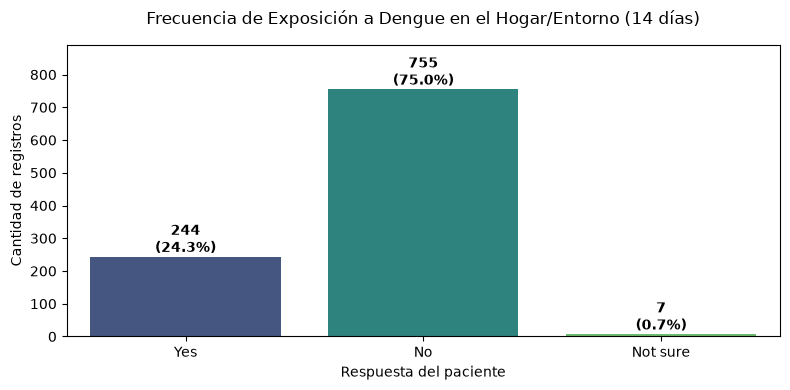

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar estilo visual
plt.figure(figsize=(8, 4))
ax = sns.countplot(
    data=df, 
    x='household_dengue_exposure_14d', 
    order=['Yes', 'No', 'Not sure'],
    palette='viridis',
    hue='household_dengue_exposure_14d',
    legend=False
)

# Añadir etiquetas con el conteo exacto y porcentaje sobre cada barra
total = len(df)
for p in ax.patches:
    conteo = int(p.get_height())
    porcentaje = 100 * conteo / total
    ax.annotate(f'{conteo}\n({porcentaje:.1f}%)', 
                (p.get_x() + p.get_width() / 2., conteo), 
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title('Frecuencia de Exposición a Dengue en el Hogar/Entorno (14 días)', pad=15)
plt.xlabel('Respuesta del paciente')
plt.ylabel('Cantidad de registros')
plt.ylim(0, df['household_dengue_exposure_14d'].value_counts().max() * 1.18)
plt.tight_layout()
plt.show()


In [54]:
# Mapear 'Yes' a 1 y agrupar 'No' + 'Not sure' en 0 (sin exposición confirmada)
mapa_exposicion = {
    'Yes': 1,
    'No': 0,
    'Not sure': 0
}

df['household_dengue_exposure_14d'] = df['household_dengue_exposure_14d'].map(mapa_exposicion)

In [56]:
df['stagnant_water'].unique()

<ArrowStringArray>
['Yes', 'No', 'Not sure']
Length: 3, dtype: str

[Text(0, 0, '739'), Text(0, 0, '170'), Text(0, 0, '97')]

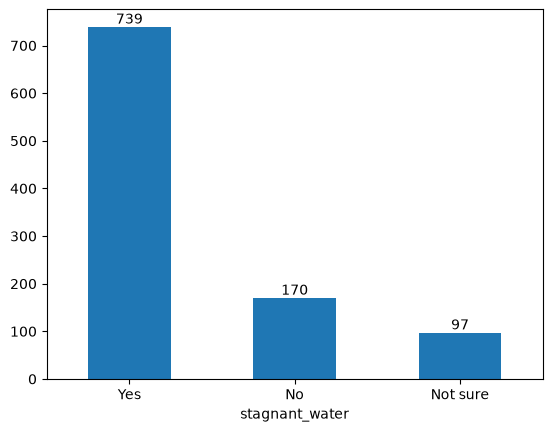

In [58]:
ax = df['stagnant_water'].value_counts(dropna=False).plot(kind='bar', rot=0)
ax.bar_label(ax.containers[0])



In [59]:
df['stagnant_water'] = df['stagnant_water'].map({'No': 0, 'Not sure': 1, 'Yes': 2})
df.head()


,age,gender,area_type,household_dengue_exposure_14d,stagnant_water,fever_days,max_temperature_f,headache_severity,retro_orbital_pain,muscle_pain,...,vomiting_per_day,early_nausea,early_rash,early_bleeding,early_abdominal_pain,early_fatigue,early_appetite_loss,early_chills,early_diarrhea,dengue_result
0,30,0,1,1,2,4,103,7,0,0,...,2,Yes,Yes,No,No,Yes,Yes,No,Yes,Dengue Positive
1,38,0,1,0,2,9,105,9,0,5,...,6,Yes,Yes,No,No,Yes,Yes,No,Yes,Dengue Positive
2,27,0,0,0,2,5,107,10,0,8,...,6,Yes,No,No,Yes,Yes,Yes,Yes,No,Dengue Positive
3,35,0,1,0,0,13,104,10,5,8,...,1,Yes,No,No,Yes,Yes,Yes,Yes,Yes,Dengue Positive
4,44,0,1,1,2,7,106,6,8,5,...,5,Yes,No,No,Yes,Yes,Yes,Yes,No,Dengue Negative


In [62]:
df['max_temperature_f'].unique()

<ArrowStringArray>
['103', '105', '107', '104', '106', '102', '101', '100', '99', '8',
 'Munshiganj']
Length: 11, dtype: str

In [63]:
df['max_temperature_f'].value_counts()

max_temperature_f
104           272
103           230
102           200
101           143
105           114
106            21
100            21
107             2
99              1
8               1
Munshiganj      1
Name: count, dtype: int64

In [64]:
# 1. Eliminar los 2 registros corruptos ('8' y 'Munshiganj')
df = df[~df['max_temperature_f'].isin(['8', 'Munshiganj'])].reset_index(drop=True)

# 2. Convertir la columna de texto a formato numérico
df['max_temperature_f'] = pd.to_numeric(df['max_temperature_f'])

# 3. Verificar tipo de dato, rango clínico y filas restantes
print(f"Tipo de dato: {df['max_temperature_f'].dtype}")
print(f"Rango: {df['max_temperature_f'].min()} °F - {df['max_temperature_f'].max()} °F")
print(f"Filas restantes: {len(df)}")

Tipo de dato: int64
Rango: 99 °F - 107 °F
Filas restantes: 1004


In [65]:
df['early_nausea'].unique()

<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

In [ ]:
df['early_nausea'] = df['early_nausea'].map({'Yes': 1, 'No': 0})

In [67]:
df['early_rash'].unique()

<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

In [68]:
df['early_rash'] = df['early_rash'].map({'Yes': 1, 'No': 0})

In [69]:
df['early_bleeding'].unique()

<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

In [ ]:
df['early_bleeding'] = df['early_bleeding'].map({'Yes': 1, 'No': 0})

In [71]:
df['early_abdominal_pain'].unique()

<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

In [72]:
df['early_abdominal_pain'] = df['early_abdominal_pain'].map({'Yes': 1, 'No': 0})

In [73]:
df['early_fatigue'].unique()

<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

In [74]:
df['early_fatigue'] = df['early_fatigue'].map({'Yes': 1, 'No': 0})

In [75]:
df['early_appetite_loss'].unique()

<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

In [76]:
df['early_appetite_loss'] = df['early_appetite_loss'].map({'Yes': 1, 'No': 0})

In [77]:
df['early_chills'].unique()

<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

In [78]:
df['early_chills'] = df['early_chills'].map({'Yes': 1, 'No': 0})

In [79]:
df['early_diarrhea'].unique()

<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

In [80]:
df['early_diarrhea'] = df['early_diarrhea'].map({'Yes': 1, 'No': 0})

In [81]:
df['dengue_result'].unique()


<ArrowStringArray>
['Dengue Positive', 'Dengue Negative']
Length: 2, dtype: str

In [82]:
# Codificar variable objetivo (Dengue Negative: 0, Dengue Positive: 1)
df['dengue_result'] = df['dengue_result'].map({
    'Dengue Negative': 0,
    'Dengue Positive': 1
})

# Verificar conteo y proporción porcentual de clases
print("Conteo de clases:")
print(df['dengue_result'].value_counts(dropna=False))

print("\nProporción (%):")
print((df['dengue_result'].value_counts(normalize=True) * 100).round(2))


Conteo de clases:
dengue_result
1    626
0    378
Name: count, dtype: int64

Proporción (%):
dengue_result
1    62.35
0    37.65
Name: proportion, dtype: float64


In [84]:
df.describe(include='all').T

,count,mean,std,min,25%,50%,75%,max
age,1004.0,34.101594,11.127003,14.0,25.0,33.0,41.0,71.0
gender,1004.0,0.246016,0.430903,0.0,0.0,0.0,0.0,1.0
area_type,1004.0,1.737052,0.602902,0.0,2.0,2.0,2.0,2.0
household_dengue_exposure_14d,1004.0,0.243028,0.429126,0.0,0.0,0.0,0.0,1.0
stagnant_water,1004.0,1.565737,0.764792,0.0,1.0,2.0,2.0,2.0
fever_days,1004.0,6.554781,2.306086,0.0,5.0,6.0,8.0,16.0
max_temperature_f,1004.0,103.017928,1.385611,99.0,102.0,103.0,104.0,107.0
headache_severity,1004.0,8.524900,1.692272,0.0,8.0,9.0,10.0,10.0
retro_orbital_pain,1004.0,4.255976,3.593116,0.0,0.0,5.0,7.0,10.0
muscle_pain,1004.0,7.451195,2.046958,0.0,6.0,8.0,9.0,10.0


In [87]:
df.describe(include='all').T.to_csv('resumen_estadistico.csv')

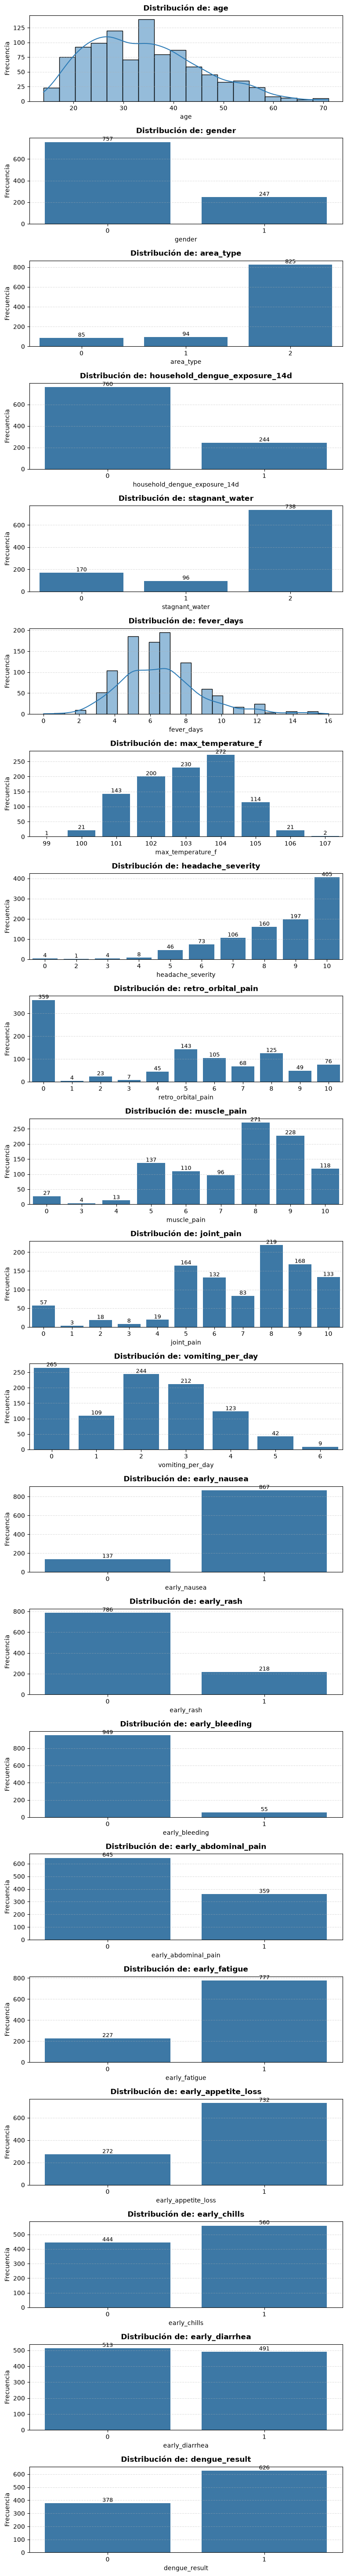

In [89]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tomar todas las columnas del DataFrame
columnas = df.columns.tolist()

# 2. Crear cuadrícula vertical dinámica (1 gráfico por fila)
fig, axes = plt.subplots(nrows=len(columnas), ncols=1, figsize=(8, 2.8 * len(columnas)))

# 3. Dibujar un histograma por cada variable
for ax, col in zip(axes, columnas):
    # Si la variable tiene pocos valores únicos (binarias o escalas 0-10), usamos barras discretas exactas
    if df[col].nunique() <= 15:
        sns.countplot(data=df, x=col, color='#2c7bb6', ax=ax)
        ax.bar_label(ax.containers[0], fontsize=9) # Agrega el conteo exacto arriba
    else:
        # Para variables continuas (age, fever_days), usamos histograma con curva de densidad
        sns.histplot(data=df, x=col, kde=True, color='#2c7bb6', ax=ax)
        
    ax.set_title(f'Distribución de: {col}', fontweight='bold', pad=8)
    ax.set_ylabel('Frecuencia')
    ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('histogramas_variables.png', dpi=300, bbox_inches='tight')
plt.show()


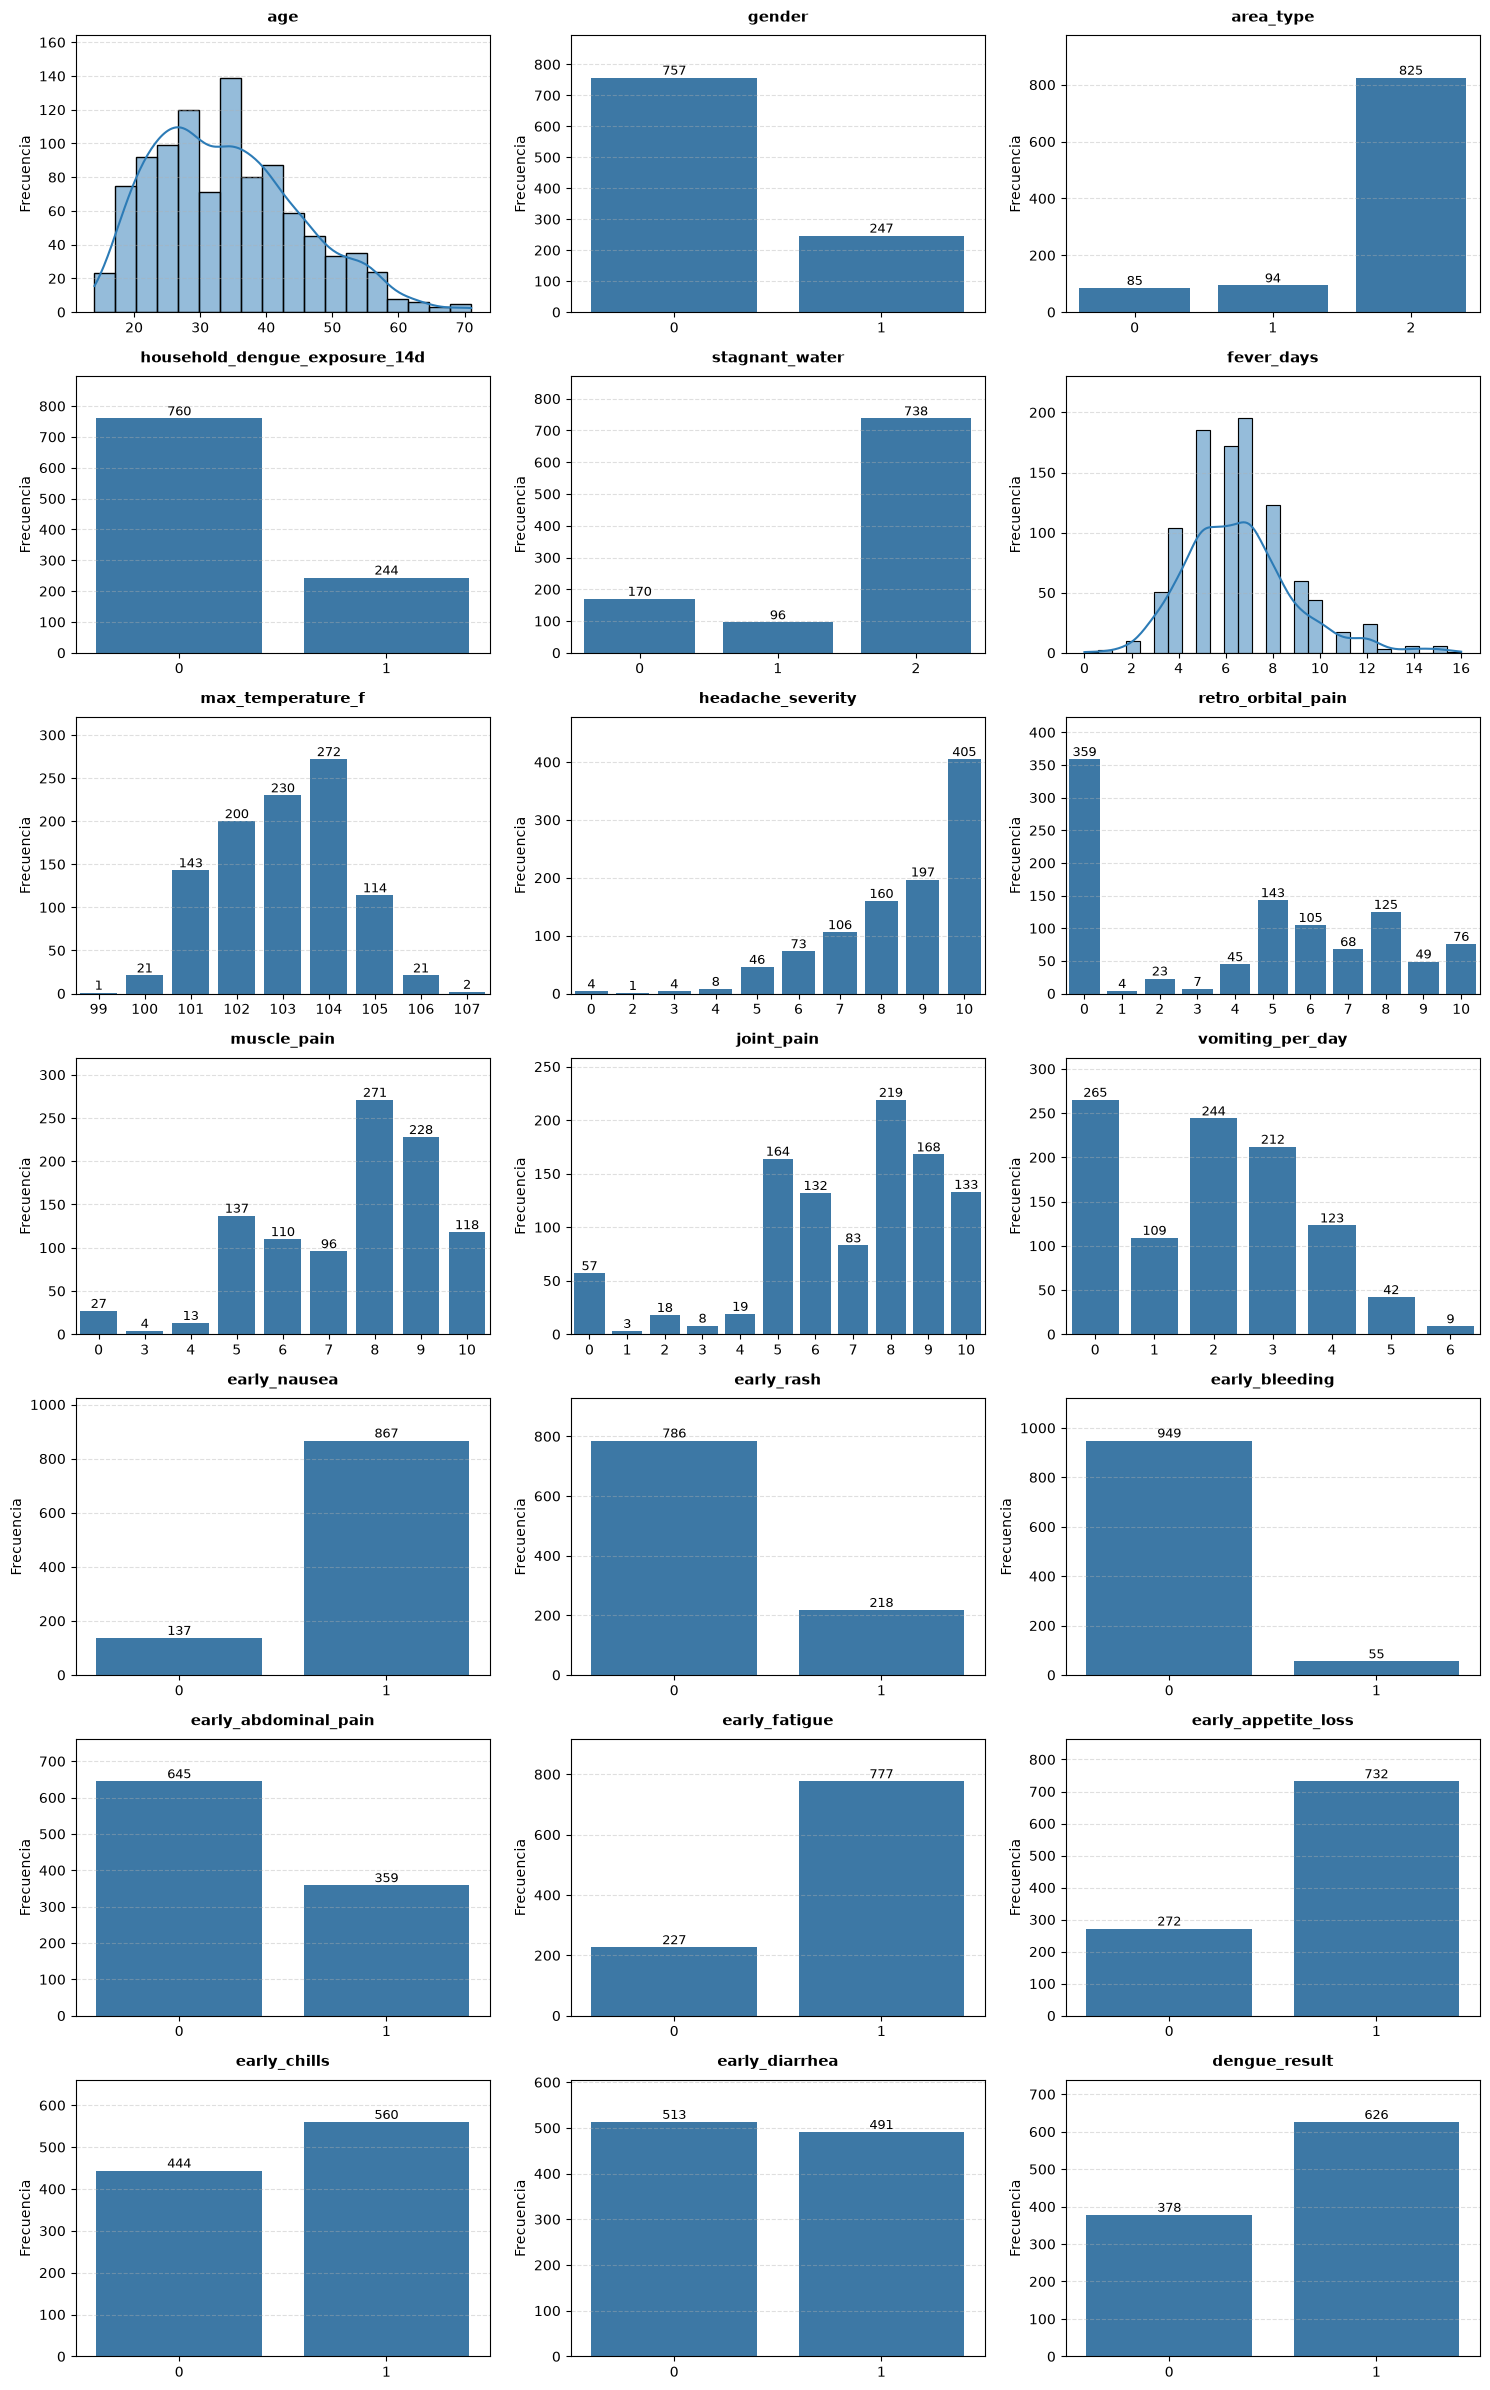

In [92]:
import matplotlib.pyplot as plt
import seaborn as sns

columnas = df.columns.tolist()
fig, axes = plt.subplots(nrows=7, ncols=3, figsize=(15, 24))
axes = axes.flatten()

for ax, col in zip(axes, columnas):
    if df[col].nunique() <= 15:
        sns.countplot(data=df, x=col, color='#2c7bb6', ax=ax)
        for c in ax.containers:
            ax.bar_label(c, fontsize=9)
    else:
        sns.histplot(data=df, x=col, kde=True, color='#2c7bb6', ax=ax)
        
    ax.set_title(col, fontweight='bold', fontsize=11, pad=10)
    ax.set_xlabel('')
    ax.set_ylabel('Frecuencia')
    ax.margins(y=0.18)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('histogramas_grid_7x3.png', dpi=300, bbox_inches='tight')
plt.show()



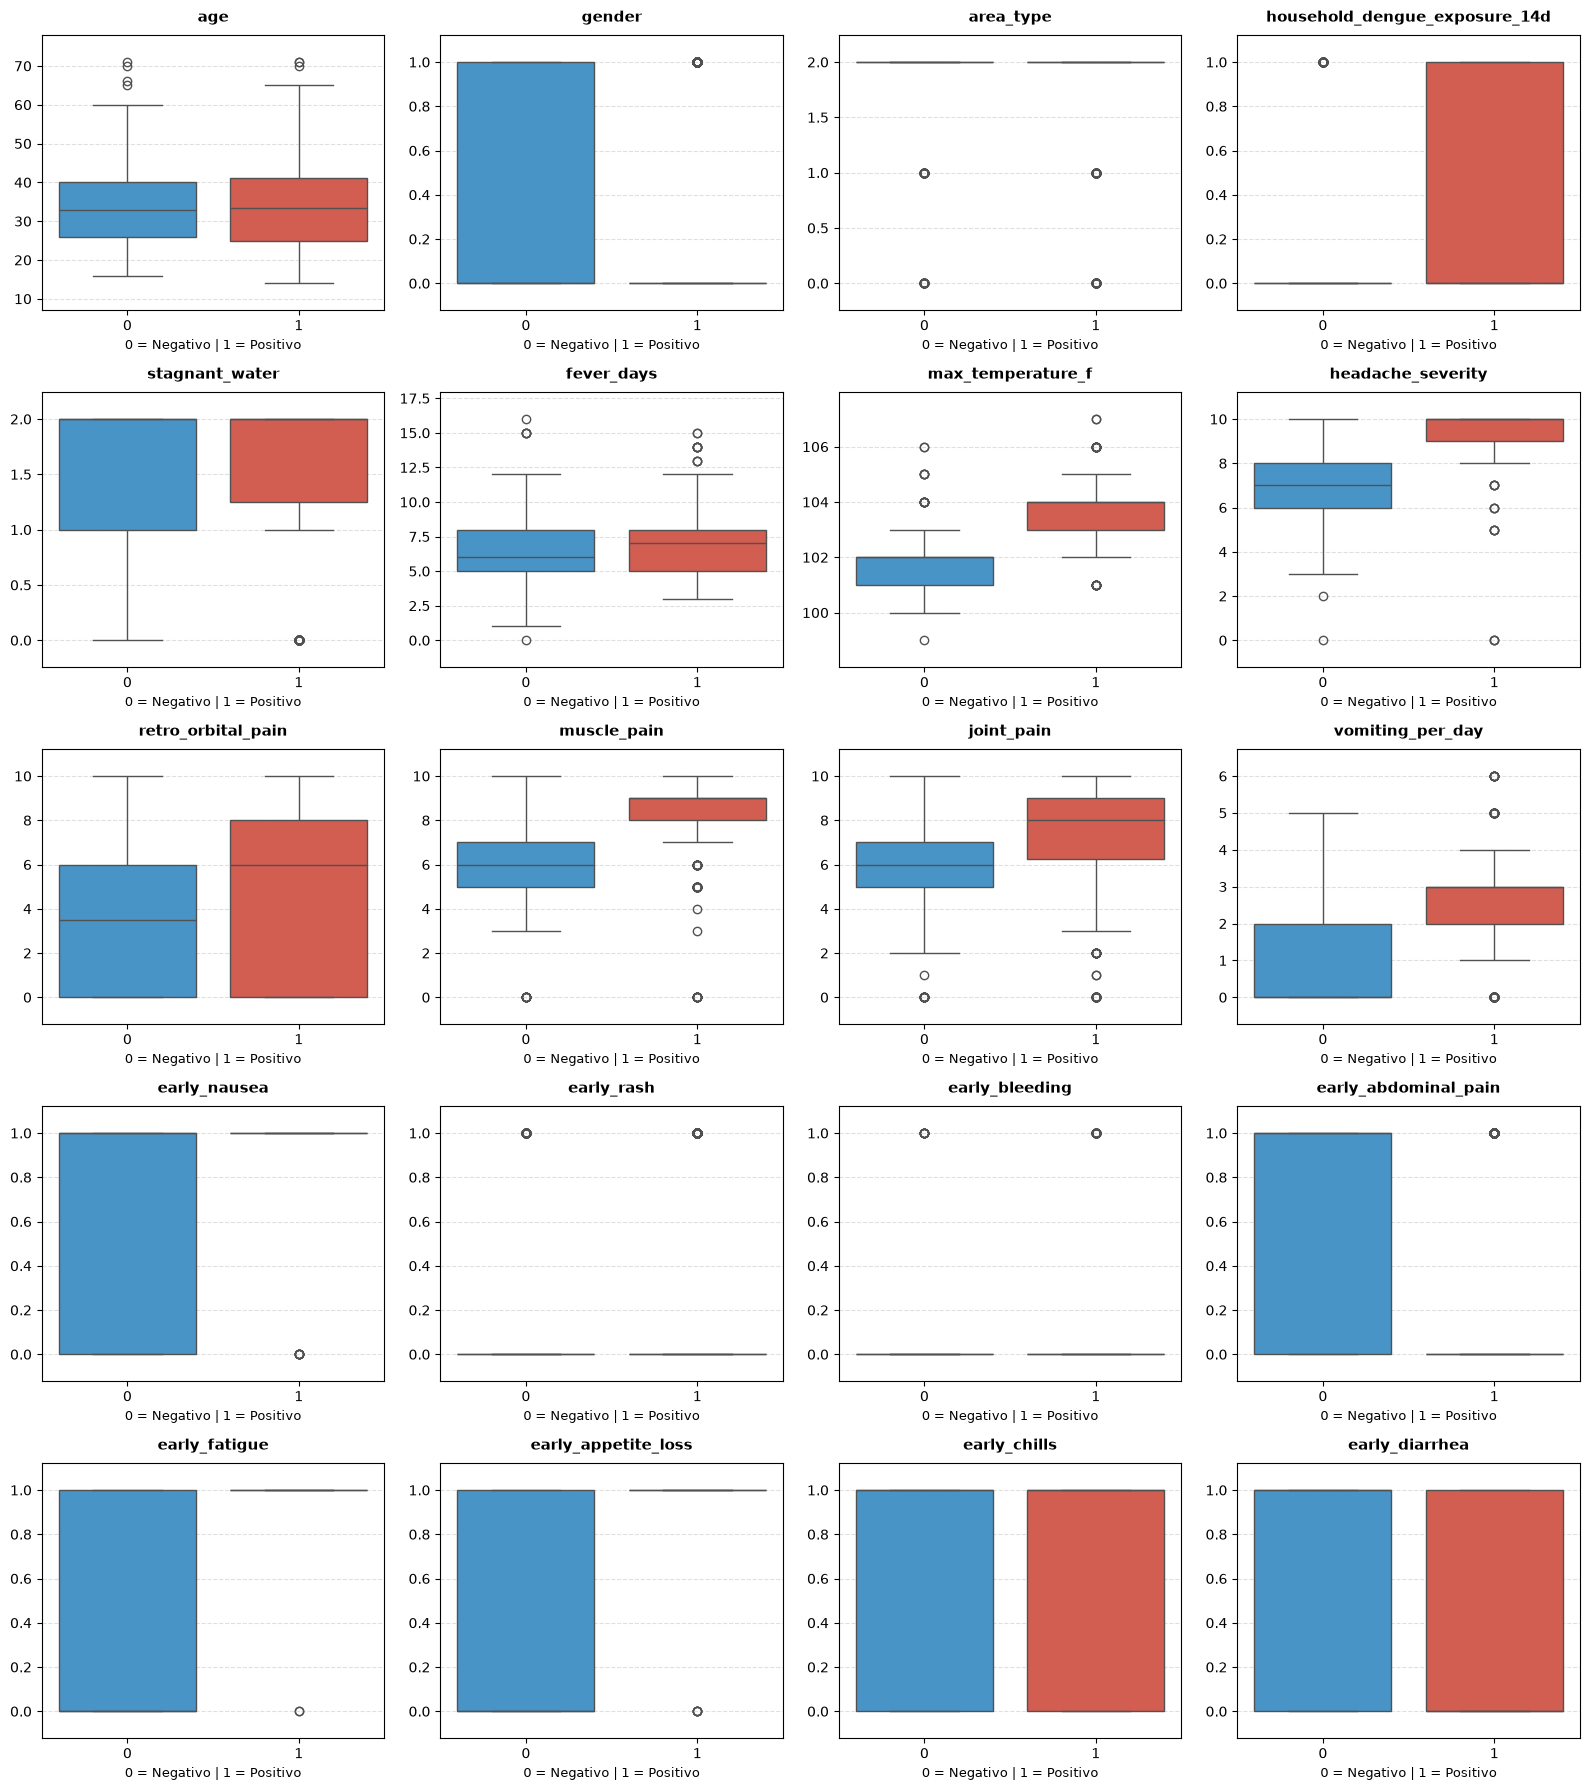

In [93]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tomar las 20 columnas predictoras
columnas = [col for col in df.columns if col != 'dengue_result']

# 2. Crear cuadrícula de 5 filas x 4 columnas (20 espacios exactos)
fig, axes = plt.subplots(nrows=5, ncols=4, figsize=(16, 18))
axes = axes.flatten()

# 3. Dibujar cada boxplot en su celda correspondiente
for ax, col in zip(axes, columnas):
    sns.boxplot(
        data=df,
        x='dengue_result',
        y=col,
        hue='dengue_result',
        palette={0: '#3498db', 1: '#e74c3c'},
        legend=False,
        ax=ax
    )
    ax.set_title(col, fontweight='bold', fontsize=11, pad=10)
    ax.set_xlabel('0 = Negativo | 1 = Positivo', fontsize=9)
    ax.set_ylabel('')
    ax.margins(y=0.12)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('boxplots_grid_5x4.png', dpi=300, bbox_inches='tight')
plt.show()


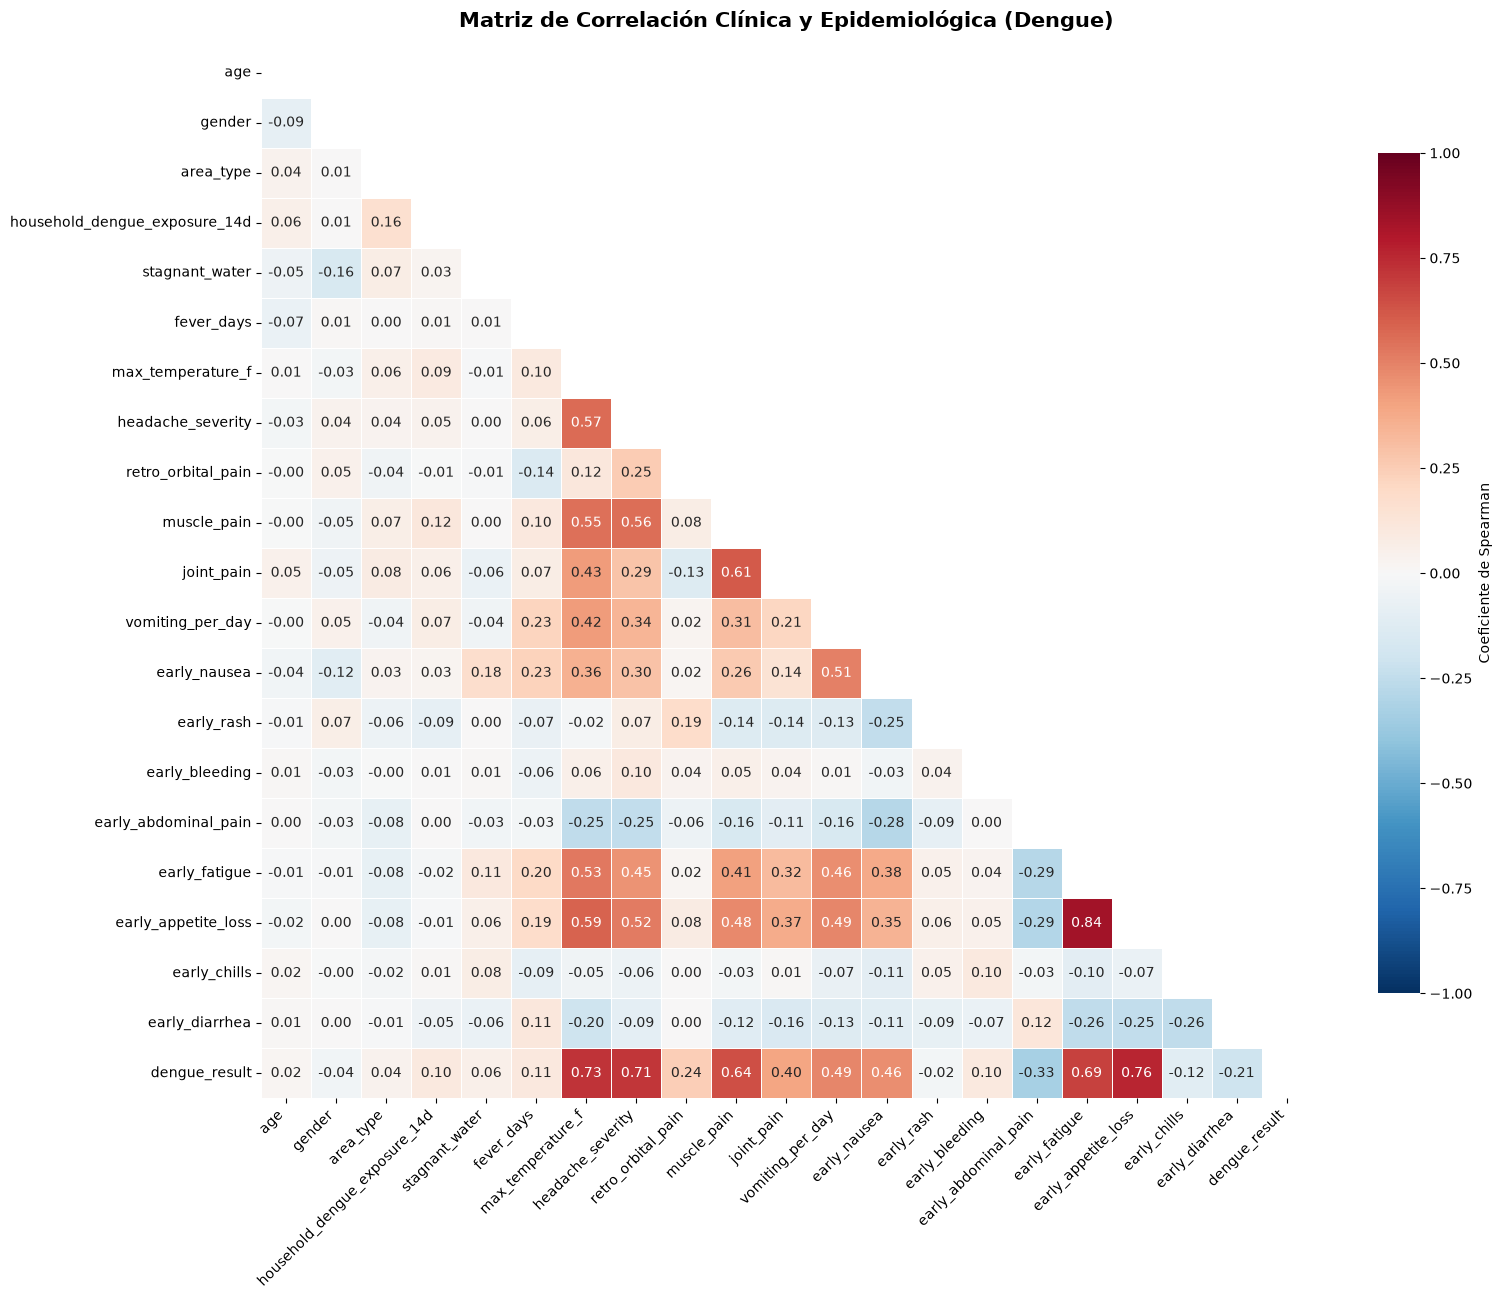

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calcular matriz de correlación (Spearman es ideal para datos clínicos mixtos)
corr = df.corr(method='spearman')

# 2. Crear máscara para ocultar el triángulo superior redundante
mask = np.triu(np.ones_like(corr, dtype=bool))

# 3. Configurar figura y dibujar el heatmap
plt.figure(figsize=(16, 13))
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r', # Rojo: correlación positiva | Azul: correlación negativa
    vmin=-1, vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8, 'label': 'Coeficiente de Spearman'}
)

plt.title('Matriz de Correlación Clínica y Epidemiológica (Dengue)', fontsize=15, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
#plt.savefig('heatmap_correlacion_dengue.png', dpi=300, bbox_inches='tight')
plt.show()


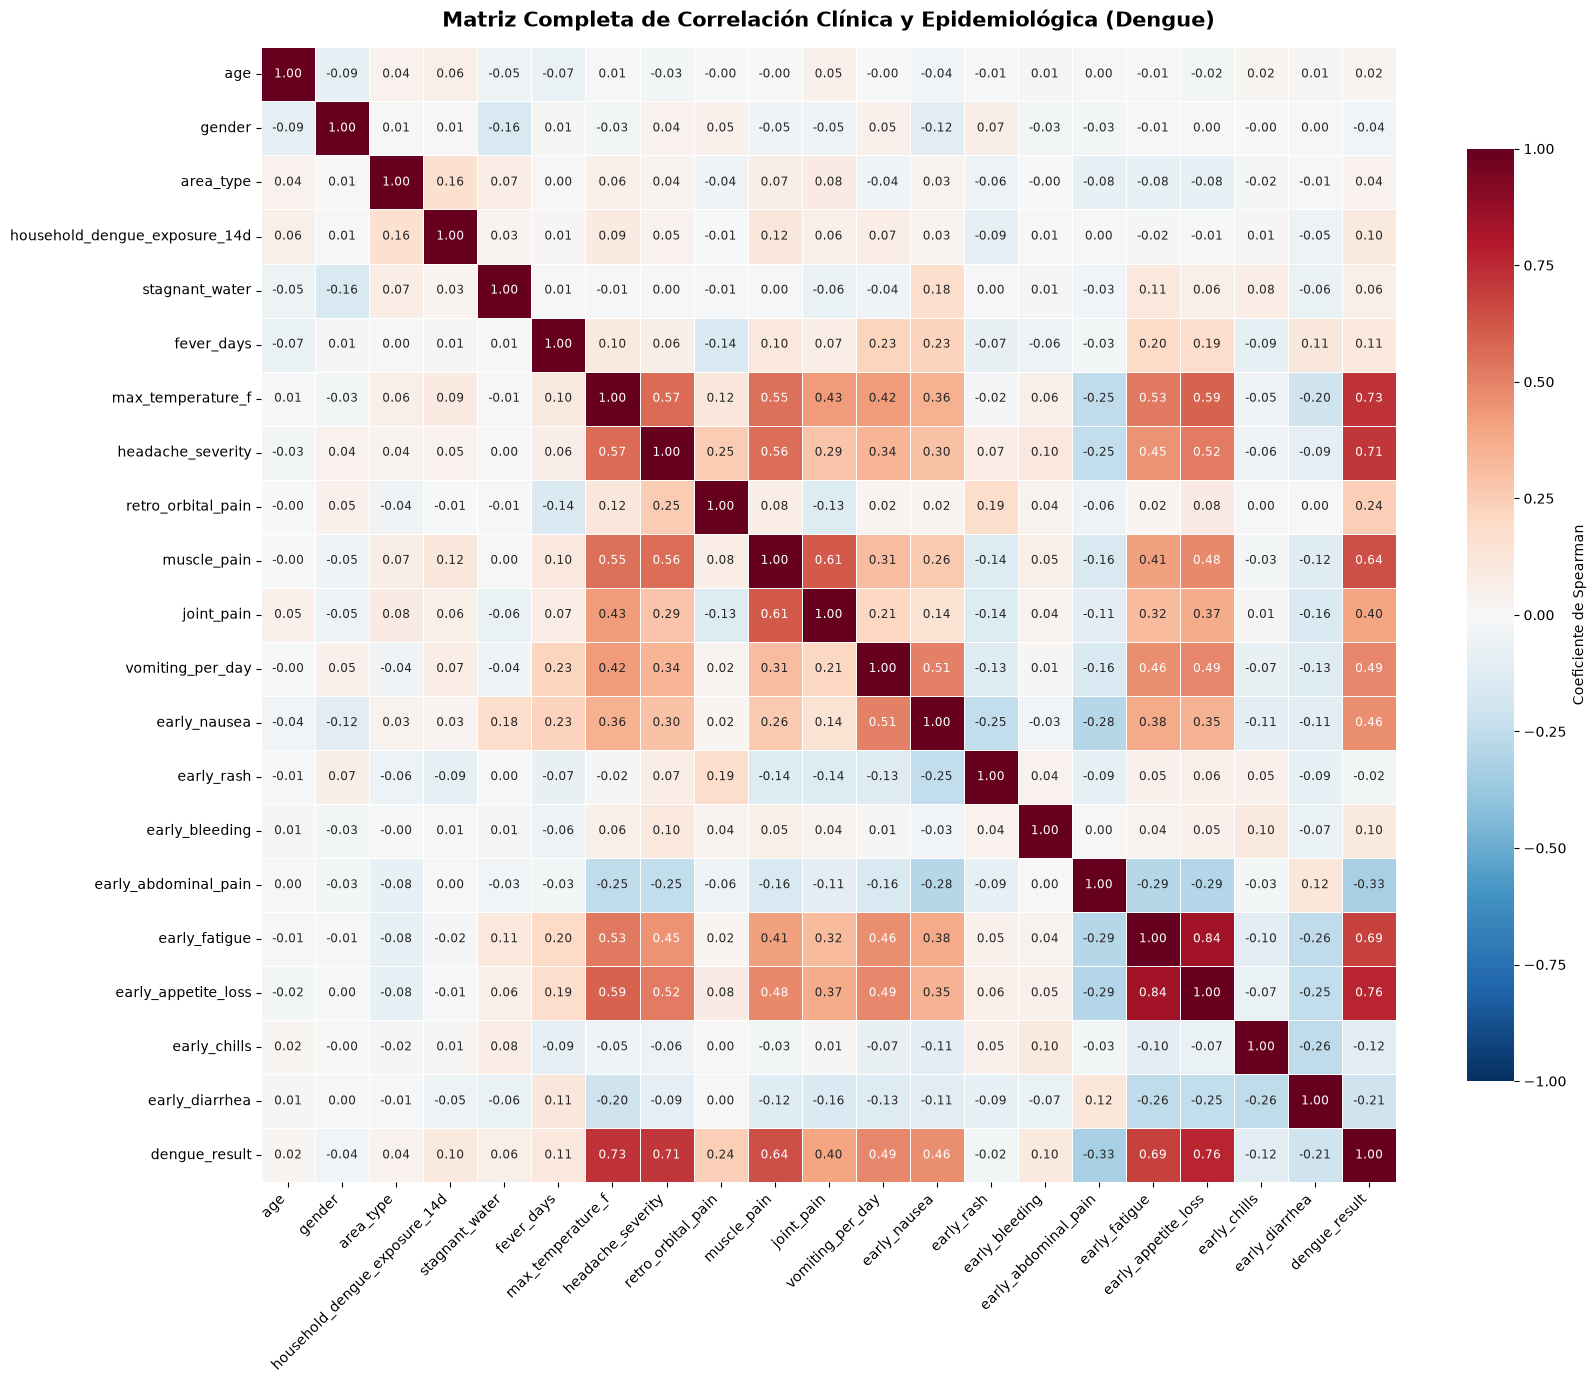

In [97]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calcular matriz de correlación de Spearman
corr = df.corr(method='spearman')

# 2. Configurar figura y dibujar el rectángulo completo (sin mask)
plt.figure(figsize=(17, 14))
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    vmin=-1, vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    annot_kws={'size': 8.5}, # Tamaño óptimo para que ningún número se monte en la matriz completa
    cbar_kws={'shrink': 0.8, 'label': 'Coeficiente de Spearman'}
)

plt.title('Matriz Completa de Correlación Clínica y Epidemiológica (Dengue)', fontsize=15, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
#plt.savefig('heatmap_completo_dengue.png', dpi=300, bbox_inches='tight')
plt.show()


2 Modelado

In [99]:
from sklearn.model_selection import train_test_split

# 1. Separar características (X) y variable objetivo (y)
X = df.drop(columns=['dengue_result'])
y = df['dengue_result']

# 2. División estratificada 80% entrenamiento / 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=13, 
    stratify=y
)

print(f"Entrenamiento: {X_train.shape[0]} registros ({y_train.mean()*100:.1f}% positivos)")
print(f"Prueba (Test): {X_test.shape[0]} registros ({y_test.mean()*100:.1f}% positivos)")


Entrenamiento: 803 registros (62.4% positivos)
Prueba (Test): 201 registros (62.2% positivos)


Modelo 1 — Regresión Logística (Optimización e Interpretabilidad)

In [100]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

# 1. Definir Pipeline (escalado dentro de CV para evitar fuga de datos)
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(solver='liblinear', max_iter=1000, random_state=42))
])

# 2. Rejilla de hiperparámetros a explorar
param_grid_lr = {
    'lr__C': [0.01, 0.1, 1, 10, 100],
    'lr__penalty': ['l1', 'l2'],
    'lr__class_weight': [None, 'balanced']
}

# 3. Búsqueda exhaustiva con Validación Cruzada Estratificada (5-Fold)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_lr = GridSearchCV(pipe_lr, param_grid_lr, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_lr.fit(X_train, y_train)

# 4. Resultados de optimización y evaluación en Test
print("Mejores hiperparámetros (Regresión Logística):", grid_lr.best_params_)
print(f"Mejor ROC-AUC en Validación Cruzada (Train): {grid_lr.best_score_:.4f}")

mejor_lr = grid_lr.best_estimator_
y_pred_lr = mejor_lr.predict(X_test)
y_prob_lr = mejor_lr.predict_proba(X_test)[:, 1]

print(f"ROC-AUC en Prueba (Test): {roc_auc_score(y_test, y_prob_lr):.4f}\n")
print(classification_report(y_test, y_pred_lr))


Mejores hiperparámetros (Regresión Logística): {'lr__C': 0.01, 'lr__class_weight': None, 'lr__penalty': 'l2'}
Mejor ROC-AUC en Validación Cruzada (Train): 0.9905
ROC-AUC en Prueba (Test): 0.9929

              precision    recall  f1-score   support

           0       0.99      0.95      0.97        76
           1       0.97      0.99      0.98       125

    accuracy                           0.98       201
   macro avg       0.98      0.97      0.97       201
weighted avg       0.98      0.98      0.98       201



c:\Users\DiegoR\anaconda3\envs\modulo3\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [101]:
import pandas as pd
import numpy as np

# Extraer los coeficientes del modelo ganador dentro del Pipeline
coeficientes = mejor_lr.named_steps['lr'].coef_[0]

df_importancia_lr = pd.DataFrame({
    'Variable': X_train.columns,
    'Coeficiente (Log-Odds)': coeficientes,
    'Odds_Ratio': np.exp(coeficientes),
    'Impacto_Absoluto': np.abs(coeficientes)
}).sort_values(by='Impacto_Absoluto', ascending=False)

print(df_importancia_lr[['Variable', 'Coeficiente (Log-Odds)', 'Odds_Ratio']].to_string(index=False))


                     Variable  Coeficiente (Log-Odds)  Odds_Ratio
          early_appetite_loss                0.525637    1.691535
            max_temperature_f                0.497412    1.644459
            headache_severity                0.485897    1.625632
                early_fatigue                0.447112    1.563789
                  muscle_pain                0.282567    1.326530
                 early_nausea                0.281268    1.324809
           retro_orbital_pain                0.253418    1.288422
             vomiting_per_day                0.238646    1.269529
         early_abdominal_pain               -0.192050    0.825265
                 early_chills               -0.130045    0.878056
               early_diarrhea               -0.104812    0.900494
household_dengue_exposure_14d                0.098674    1.103706
               early_bleeding                0.080611    1.083949
               stagnant_water                0.063562    1.065626
          

Modelo 2 — Random Forest (Optimización de Hiperparámetros no Lineales)

In [104]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import classification_report, roc_auc_score

# 1. Definir el modelo base
rf = RandomForestClassifier(random_state=42)

# 2. Rejilla de hiperparámetros enfocada en controlar sobreajuste
param_grid_rf = {
    'n_estimators': list((100, 200, 300)),
    'max_depth': list((4, 6, 8, None)),
    'min_samples_split': list((2, 5, 10)),
    'min_samples_leaf': list((1, 2, 4)),
    'max_features': list(('sqrt', 'log2'))
}

# 3. Búsqueda con Validación Cruzada Estratificada (5-Fold)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_rf = GridSearchCV(rf, param_grid_rf, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_rf.fit(X_train, y_train)

# 4. Resultados de optimización y evaluación en Test
print("Mejores hiperparámetros (Random Forest):", grid_rf.best_params_)
print(f"Mejor ROC-AUC en Validación Cruzada (Train): {grid_rf.best_score_:.4f}")

mejor_rf = grid_rf.best_estimator_
y_pred_rf = mejor_rf.predict(X_test)
y_prob_rf = mejor_rf.predict_proba(X_test)[:, 1]

print(f"ROC-AUC en Prueba (Test): {roc_auc_score(y_test, y_prob_rf):.4f}\n")
print(classification_report(y_test, y_pred_rf))


Mejores hiperparámetros (Random Forest): {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}
Mejor ROC-AUC en Validación Cruzada (Train): 0.9951
ROC-AUC en Prueba (Test): 0.9959

              precision    recall  f1-score   support

           0       1.00      0.97      0.99        76
           1       0.98      1.00      0.99       125

    accuracy                           0.99       201
   macro avg       0.99      0.99      0.99       201
weighted avg       0.99      0.99      0.99       201



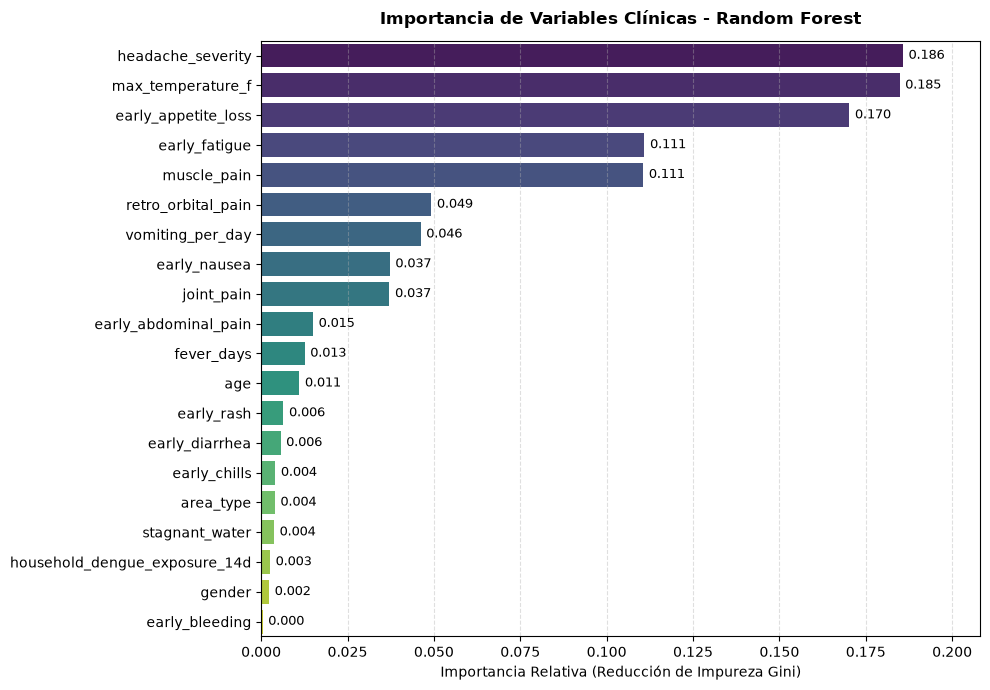

In [106]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extraer importancia de variables
importancias = pd.DataFrame({
    'Variable': X_train.columns,
    'Importancia': mejor_rf.feature_importances_
}).sort_values(by='Importancia', ascending=False)

# Graficar ranking visual con valores numéricos exactos
plt.figure(figsize=(10, 7))
ax = sns.barplot(data=importancias, x='Importancia', y='Variable', palette='viridis', hue='Variable', legend=False)

# Agregar el número exacto (3 decimales) a cada barra
for c in ax.containers:
    ax.bar_label(c, fmt='%.3f', padding=4, fontsize=9)

ax.margins(x=0.12) # Margen derecho para que no se corten los números
plt.title('Importancia de Variables Clínicas - Random Forest', fontweight='bold', pad=12)
plt.xlabel('Importancia Relativa (Reducción de Impureza Gini)')
plt.ylabel('')
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig('importancia_rf.png', dpi=300, bbox_inches='tight')
plt.show()


Modelo 3 — Gradient Boosting (Optimización Secuencial)

In [107]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import classification_report, roc_auc_score

# 1. Definir modelo base
gb = GradientBoostingClassifier(random_state=42)

# 2. Rejilla de hiperparámetros con control de tasa de aprendizaje y profundidad
param_grid_gb = {
    'n_estimators': list((100, 200)),
    'learning_rate': list((0.05, 0.1, 0.2)),
    'max_depth': list((2, 3, 4)),
    'subsample': list((0.8, 1.0))
}

# 3. Validación Cruzada Estratificada (5-Fold)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_gb = GridSearchCV(gb, param_grid_gb, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_gb.fit(X_train, y_train)

# 4. Resultados y evaluación en Test
print("Mejores hiperparámetros (Gradient Boosting):", grid_gb.best_params_)
print(f"Mejor ROC-AUC en Validación Cruzada (Train): {grid_gb.best_score_:.4f}")

mejor_gb = grid_gb.best_estimator_
y_pred_gb = mejor_gb.predict(X_test)
y_prob_gb = mejor_gb.predict_proba(X_test)[:, 1]

print(f"ROC-AUC en Prueba (Test): {roc_auc_score(y_test, y_prob_gb):.4f}\n")
print(classification_report(y_test, y_pred_gb))

Mejores hiperparámetros (Gradient Boosting): {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 1.0}
Mejor ROC-AUC en Validación Cruzada (Train): 0.9949
ROC-AUC en Prueba (Test): 0.9975

              precision    recall  f1-score   support

           0       0.99      0.97      0.98        76
           1       0.98      0.99      0.99       125

    accuracy                           0.99       201
   macro avg       0.99      0.98      0.98       201
weighted avg       0.99      0.99      0.99       201



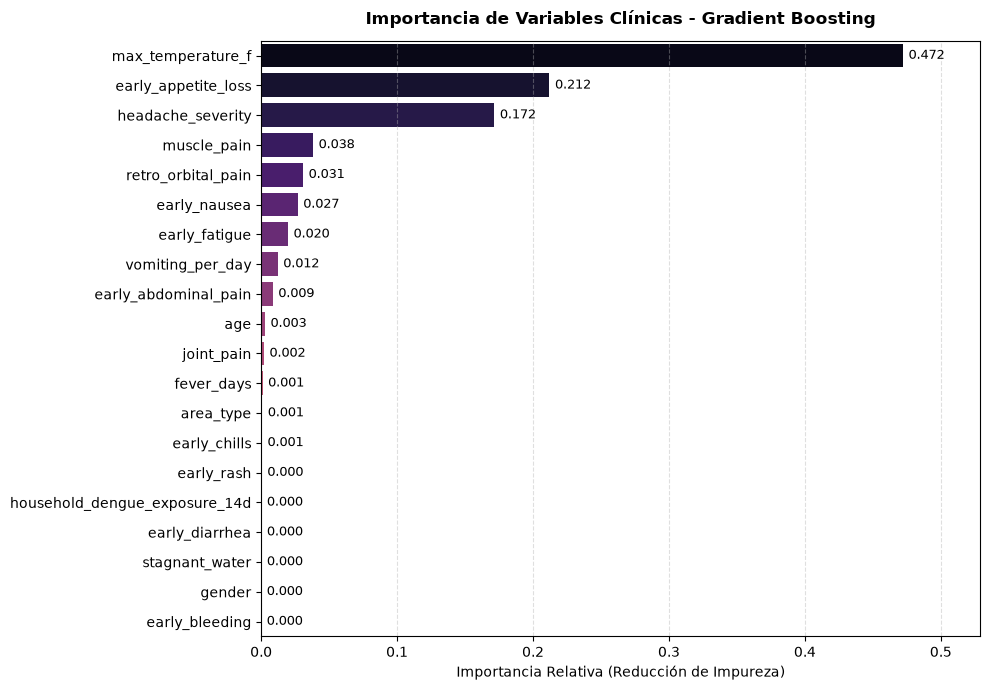

In [108]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extraer importancia de variables de Gradient Boosting
importancias_gb = pd.DataFrame({
    'Variable': X_train.columns,
    'Importancia': mejor_gb.feature_importances_
}).sort_values(by='Importancia', ascending=False)

# 2. Graficar ranking visual con valores numéricos exactos
plt.figure(figsize=(10, 7))
ax = sns.barplot(
    data=importancias_gb, 
    x='Importancia', 
    y='Variable', 
    palette='magma', 
    hue='Variable', 
    legend=False
)

# Agregar el valor exacto (3 decimales) al final de cada barra
for c in ax.containers:
    ax.bar_label(c, fmt='%.3f', padding=4, fontsize=9)

ax.margins(x=0.12)
plt.title('Importancia de Variables Clínicas - Gradient Boosting', fontweight='bold', pad=12)
plt.xlabel('Importancia Relativa (Reducción de Impureza)')
plt.ylabel('')
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig('importancia_gb.png', dpi=300, bbox_inches='tight')
plt.show()


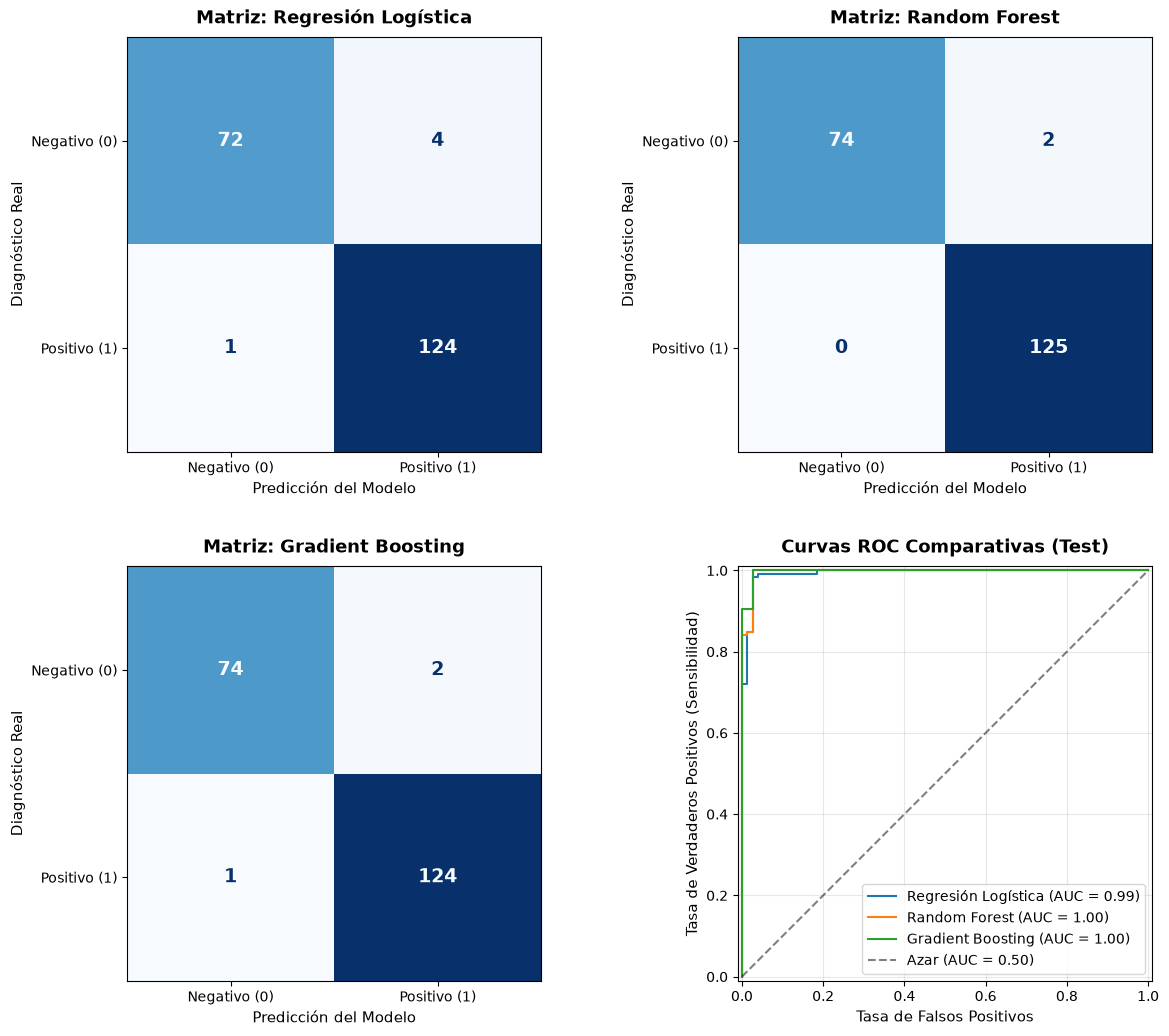

In [111]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

# Cambiar a cuadrícula 2x2 para que cada gráfico tenga espacio amplio
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(13, 11))
axes = axes.flatten()

modelos_eval = [
    ('Regresión Logística', mejor_lr),
    ('Random Forest', mejor_rf),
    ('Gradient Boosting', mejor_gb)
]

# 1. Dibujar las 3 matrices de confusión en los primeros 3 espacios
for ax, (nombre, mod) in zip(axes[:3], modelos_eval):
    ConfusionMatrixDisplay.from_estimator(
        mod, X_test, y_test,
        display_labels=['Negativo (0)', 'Positivo (1)'],
        cmap='Blues',
        colorbar=False,
        ax=ax,
        text_kw={'fontsize': 14, 'fontweight': 'bold'}
    )
    ax.set_title(f'Matriz: {nombre}', fontweight='bold', fontsize=13, pad=10)
    ax.set_xlabel('Predicción del Modelo', fontsize=11)
    ax.set_ylabel('Diagnóstico Real', fontsize=11)

# 2. Dibujar las curvas ROC comparativas en el cuarto espacio (abajo a la derecha)
ax_roc = axes[3]
for nombre, mod in modelos_eval:
    RocCurveDisplay.from_estimator(mod, X_test, y_test, name=nombre, ax=ax_roc)

ax_roc.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Azar (AUC = 0.50)')
ax_roc.set_title('Curvas ROC Comparativas (Test)', fontweight='bold', fontsize=13, pad=10)
ax_roc.set_xlabel('Tasa de Falsos Positivos', fontsize=11)
ax_roc.set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad)', fontsize=11)
ax_roc.legend(loc='lower right', fontsize=10)
ax_roc.grid(alpha=0.3)

# Añadir espaciado generoso entre filas y columnas
plt.tight_layout(pad=3.0)
plt.savefig('evaluacion_final_modelos_dengue_2x2.png', dpi=300, bbox_inches='tight')
plt.show()


Exportar el modelo

In [112]:
import joblib

# Empaquetar el modelo junto con el orden exacto de las variables y métricas clave
artefacto_modelo = {
    'modelo': mejor_rf,
    'columnas': X_train.columns.tolist(),
    'version': '1.0_RF_Dengue',
    'roc_auc_test': 0.9959,
    'sensibilidad_test': 1.00
}

# Guardar en disco
nombre_archivo = 'modelo_dengue_random_forest.joblib'
joblib.dump(artefacto_modelo, nombre_archivo)

print(f"Modelo exportado exitosamente en: {nombre_archivo}")
print(f"Total de variables requeridas para inferencia: {len(artefacto_modelo['columnas'])}")


Modelo exportado exitosamente en: modelo_dengue_random_forest.joblib
Total de variables requeridas para inferencia: 20


In [113]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1004 entries, 0 to 1003
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   age                            1004 non-null   int64
 1   gender                         1004 non-null   int64
 2   area_type                      1004 non-null   int64
 3   household_dengue_exposure_14d  1004 non-null   int64
 4   stagnant_water                 1004 non-null   int64
 5   fever_days                     1004 non-null   int64
 6   max_temperature_f              1004 non-null   int64
 7   headache_severity              1004 non-null   int64
 8   retro_orbital_pain             1004 non-null   int64
 9   muscle_pain                    1004 non-null   int64
 10  joint_pain                     1004 non-null   int64
 11  vomiting_per_day               1004 non-null   int64
 12  early_nausea                   1004 non-null   int64
 13  early_rash                   